# Use viewmastR with large query objects

A query of hundreds of thousands of cells, or millions, does not need to fit in memory. Open it on disk
(`backed="r"`), train the model once, and let `viewmastR_infer()` read and label the query
in row chunks. This tutorial follows the R article
[How to use viewmastR with large query objects](https://furlan-lab.github.io/viewmastR/articles/BigQuery.html).

| Role | Dataset |
|---|---|
| Reference | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Query | BoneMarrowMap atlas (Zeng et al. 2025), 263,159 bone marrow cells from six studies, raw counts in h5ad, downloaded on first use (3.7 GB) |

BoneMarrowMap includes the Granja et al. 2019 cells, so part of the query overlaps the
reference. This tutorial is about scale and memory, not accuracy. To label your own large
query, open it the same way: `anndata.read_h5ad(path, backed="r")`.

In [1]:
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

cfg = td.config()
label = cfg.get("greenleaf_label", "celltype")
ref = td.greenleaf_reference()
query = td.large_query()
print(f"query: {query.n_obs:,} cells x {query.n_vars:,} genes, on disk")

query: 263,159 cells x 34,009 genes, on disk


## Train once

Feature selection on the reference keeps the example light; any gene list works. Only
genes present in the query are kept.

In [2]:
vm.calculate_feature_dispersion(ref)
vm.select_features(ref, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
genes = set(query.var_names)
vg = [g for g in vm.get_selected_features(ref) if g in genes]
model_dir = Path(tempfile.mkdtemp()) / "model"
res = vm.viewmastR(None, ref, label, selected_features=vg, max_epochs=4, train_only=True, model_dir=model_dir)
print(f"{len(vg)} features; training took {res.seconds:.0f} s")

viewmastR: 10000 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 90.025% | validation accuracy 96.008%]


[epoch 2 | train accuracy 97.618% | validation accuracy 96.641%]


[epoch 3 | train accuracy 98.723% | validation accuracy 96.834%]


10000 features; training took 10 s


[epoch 4 | train accuracy 99.367% | validation accuracy 96.820%]


## Infer in chunks

`chunk_size` sets how many cells are read and labelled at a time. It bounds memory; it
does not change the result. Two chunk sizes give identical labels.

In [3]:
timing = {}
for col, size in (("test1", 20_000), ("test2", 200_000)):
    t0 = time.time()
    vm.viewmastR_infer(query, model_dir, vg, query_celldata_col=col, chunk_size=size)
    timing[size] = time.time() - t0
    print(f"chunk_size={size:,}: {timing[size]:.0f} s")
same = (query.obs["test1"].astype(str) == query.obs["test2"].astype(str)).all()
print("identical labels:", same)

chunk_size=20,000: 30 s


chunk_size=200,000: 22 s
identical labels: True


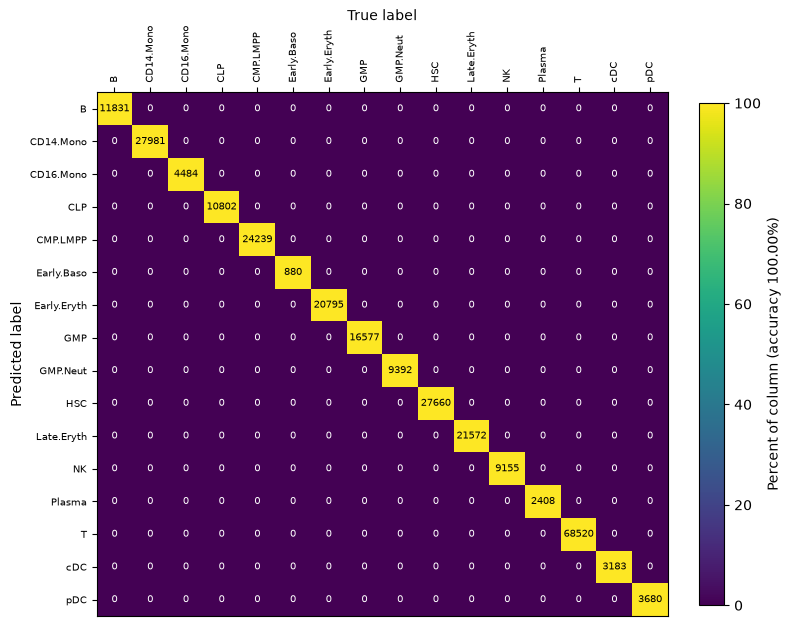

In [4]:
vm.confusion_matrix(query.obs["test1"], query.obs["test2"])
plt.show()

## Predicted composition

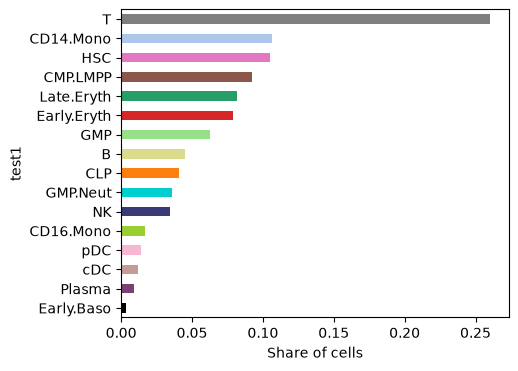

In [5]:
frac = query.obs["test1"].value_counts(normalize=True).sort_values()
frac.plot.barh(figsize=(5, 4), color=[vm.palette.color(t) for t in frac.index])
plt.xlabel("Share of cells")
plt.show()

The atlas carries its own broad labels (`CellType_Broad`), so the predictions can be
compared with them.

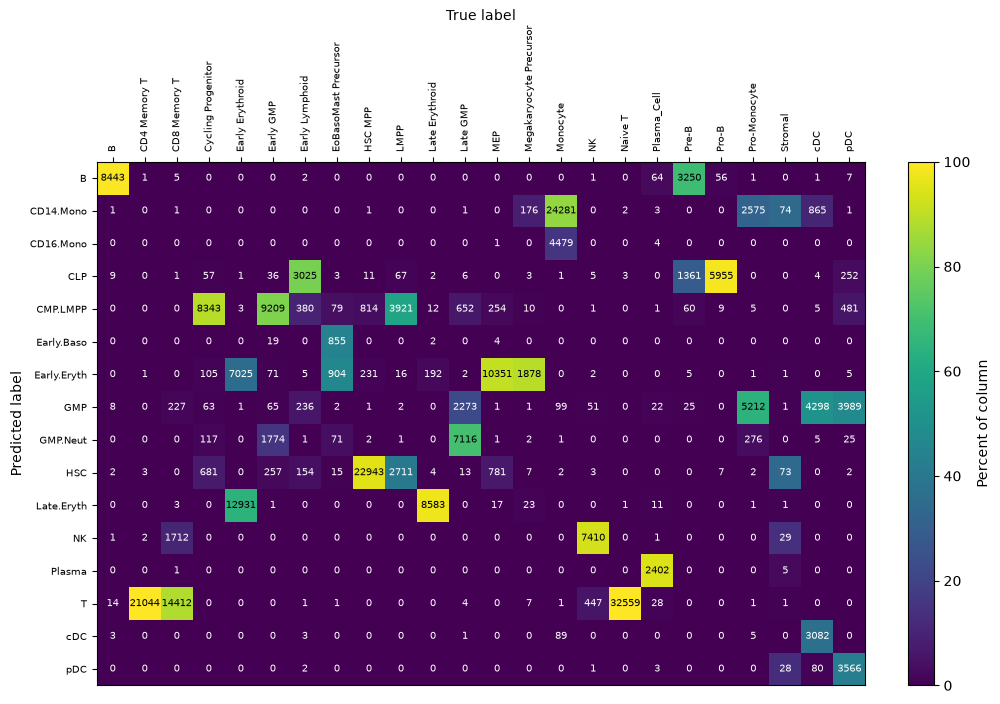

In [6]:
vm.confusion_matrix(query.obs["test1"], query.obs["CellType_Broad"])
plt.show()

## Versions

In [7]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
